In [1]:
%pip install torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 98.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 94.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 59.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 44.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 101.7 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitl

In [2]:
pip install gdown

In [42]:
import gdown
import torch
import pandas as pd
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import zipfile
import shutil
import os
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report
from torchvision import models
from torchvision.models import MobileNet_V2_Weights


In [4]:
file_id = '1owrFL0-HaCb6XVhnpme0pel2sGPCv05J'
url = f'https://drive.google.com/uc?id={file_id}'
output = 'dataset.zip'
gdown.download(url, output, quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1owrFL0-HaCb6XVhnpme0pel2sGPCv05J
From (redirected): https://drive.google.com/uc?id=1owrFL0-HaCb6XVhnpme0pel2sGPCv05J&confirm=t&uuid=35b2e815-89d8-40bb-ba7c-79467fcb38aa
To: /content/dataset.zip
100%|██████████| 135M/135M [00:02<00:00, 48.2MB/s]


'dataset.zip'

In [5]:
with zipfile.ZipFile('dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('dataset_folder')

In [6]:
macosx_path = 'dataset_folder/__MACOSX'
if os.path.exists(macosx_path):
    shutil.rmtree(macosx_path)

In [7]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])  # normalize to [-1, 1]
])

train_dataset = datasets.ImageFolder(root='dataset_folder/food11/train', transform=transform)
test_dataset = datasets.ImageFolder(root='dataset_folder/food11/test', transform=transform)
validation_dataset = datasets.ImageFolder(root = 'dataset_folder/food11/validation', transform= transform)

test_loader = DataLoader(test_dataset, batch_size=32, shuffle=True)


In [8]:
img, label = train_dataset[0]
print(img,label,img.shape)

tensor([[[0.9216, 0.9137, 0.9294,  ..., 0.9216, 0.9373, 0.9294],
         [0.9216, 0.9294, 0.9137,  ..., 0.9216, 0.9294, 0.9216],
         [0.9137, 0.9059, 0.8431,  ..., 0.8588, 0.9216, 0.9294],
         ...,
         [0.8902, 0.9059, 0.8824,  ..., 0.8510, 0.9216, 0.9294],
         [0.8980, 0.9059, 0.9137,  ..., 0.8980, 0.9216, 0.9216],
         [0.8980, 0.8902, 0.9059,  ..., 0.9059, 0.9216, 0.9373]],

        [[0.9765, 0.9686, 0.9843,  ..., 0.9608, 0.9765, 0.9686],
         [0.9765, 0.9843, 0.9686,  ..., 0.9608, 0.9686, 0.9608],
         [0.9686, 0.9608, 0.8980,  ..., 0.8980, 0.9608, 0.9686],
         ...,
         [0.9765, 0.9843, 0.9294,  ..., 0.8980, 0.9608, 0.9686],
         [0.9843, 0.9922, 0.9686,  ..., 0.9686, 0.9765, 0.9608],
         [0.9922, 0.9765, 0.9686,  ..., 0.9765, 0.9843, 0.9843]],

        [[0.9137, 0.9059, 0.9216,  ..., 0.9059, 0.9216, 0.9137],
         [0.9137, 0.9216, 0.9059,  ..., 0.9059, 0.9137, 0.9059],
         [0.9059, 0.8980, 0.8353,  ..., 0.8431, 0.9059, 0.

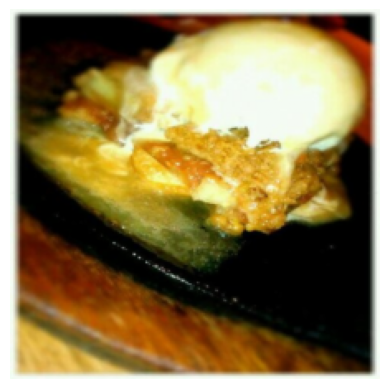

In [9]:
image_tensor = img * 0.5 + 0.5
plt.imshow(image_tensor.permute(1, 2, 0).numpy())
plt.axis('off')
plt.show()

# **PART 1**

In [10]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=11, dropout_rate=0):
        super(SimpleCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(
            nn.Linear(512 * 7 * 7, 512),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x

The SimpleCNN class defines a deep Convolutional Neural Network (CNN) designed for an 11-class image classification task. The feature extractor part consists of 5 convolutional blocks, each including a Conv2D layer, Batch Normalization, a ReLU activation, and MaxPooling. This structure progressively processes the input 3-channel (RGB) images, extracting increasingly abstract features at each stage. The classifier part includes two fully connected layers: the first Linear layer reduces the 512×7×7 feature map to 512 units, followed by a ReLU activation and Dropout layer; the final Linear layer maps the features to 11 output classes. The model’s goal is to predict the class of each input image based on the high-level features learned. The dropout rate is adjustable and helps mitigate overfitting during training.

In [11]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, downsample=False):
        super(ResidualBlock, self).__init__()
        stride = 2 if downsample else 1

        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, stride=stride)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU()

        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.downsample = downsample
        self.identity = nn.Sequential()
        if downsample or in_channels != out_channels:
            self.identity = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        identity = self.identity(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += identity
        out = self.relu(out)

        return out

class ResidualCNN(nn.Module):
    def __init__(self, num_classes=11,dropout_rate = 0.0):
        super(ResidualCNN, self).__init__()
        self.layer1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.res_block1 = ResidualBlock(32, 64, downsample=True)
        self.res_block2 = ResidualBlock(64, 128, downsample=True)
        self.res_block3 = ResidualBlock(128, 256, downsample=True)
        self.res_block4 = ResidualBlock(256, 512, downsample=True)

        self.classifier = nn.Sequential(
            nn.Linear(512 * 7 * 7, 512),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.layer1(x)
        x = self.res_block1(x)
        x = self.res_block2(x)
        x = self.res_block3(x)
        x = self.res_block4(x)

        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x

The ResidualCNN class implements a deep Convolutional Neural Network that leverages residual connections to improve learning for an 11-class image classification task. The network starts with an initial convolutional block that processes the 3-channel input image, followed by 4 stacked ResidualBlocks. Each residual block contains two convolutional layers with Batch Normalization and ReLU activations, along with a skip connection that allows the input to bypass these layers, effectively mitigating the vanishing gradient problem. Each block also applies downsampling (via stride=2) to reduce spatial dimensions while increasing feature depth, progressing from 32 to 512 channels. The classifier part includes two fully connected layers: the first reduces the flattened 512×7×7 feature map to 512 units with a ReLU and Dropout layer; the final layer outputs the class probabilities. By integrating skip connections and progressive downsampling, this architecture facilitates deeper learning and more robust feature extraction compared to a standard CNN.

In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def train_model(model, train_loader, val_loader, lr=1e-3, num_epochs=50):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_losses, val_losses = [], []
    train_accs, val_accs = [], []

    for epoch in range(num_epochs):
        model.train()
        correct, total, epoch_loss = 0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            correct += predicted.eq(labels).sum().item()
            total += labels.size(0)

        train_loss = epoch_loss / total
        train_acc = correct / total
        train_losses.append(train_loss)
        train_accs.append(train_acc)

        # Validation
        model.eval()
        correct, total, val_loss = 0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                _, predicted = outputs.max(1)
                correct += predicted.eq(labels).sum().item()
                total += labels.size(0)

        val_loss /= total
        val_acc = correct / total
        val_losses.append(val_loss)
        val_accs.append(val_acc)

        print(f"Epoch [{epoch+1}/{num_epochs}] "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

    return [train_losses, val_losses, train_accs, val_accs]

The train_model function trains a given PyTorch model using a specified training and validation data loader. It runs for a defined number of epochs (default 50), using the CrossEntropyLoss as the loss function and the Adam optimizer. In each epoch, it performs a full training loop (with gradient updates) and then evaluates the model on the validation set without updating weights. The function tracks and stores loss and accuracy metrics for both training and validation, printing a summary at the end of each epoch. Finally, it returns lists of losses and accuracies for further analysis or plotting.

In this study, I experimented with two different batch sizes (32 and 64) and three learning rates (1e-3, 1e-4, and 1e-5) to observe their impact on model performance. The batch sizes were chosen to balance between computational efficiency and stable gradient updates: a batch size of 32 is a common default that offers reliable performance, while 64 was tested to evaluate the effect of larger batches on convergence. For the learning rate, 1e-3 is a standard starting point for the Adam optimizer, while 1e-4 and 1e-5 were included to examine whether smaller learning rates provide better fine-grained updates and more stable training, especially in deeper models. These parameter combinations help identify optimal settings for achieving high validation accuracy and stable loss convergence.

In [13]:
batch_sizes = [32, 64]
learning_rates = [1e-3, 1e-4, 1e-5]

results = {}

for batch_size in batch_sizes:
    for lr in learning_rates:

        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        validation_loader = DataLoader(validation_dataset, batch_size=batch_size, shuffle=True)

        model = SimpleCNN(num_classes=11)
        print(f"\n===> Training with lr={lr}, batch_size={batch_size}")
        result = train_model(model, train_loader, validation_loader, lr)

        train_loss, val_loss, train_acc, val_acc = result

        key = f"lr_{lr}_bs_{batch_size}"
        results[key] = {
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_acc": train_acc,
            "val_acc": val_acc
        }


===> Training with lr=0.001, batch_size=32
Epoch [1/50] Train Loss: 4.8085, Train Acc: 0.1191 | Val Loss: 2.6434, Val Acc: 0.1236
Epoch [2/50] Train Loss: 2.3546, Train Acc: 0.1686 | Val Loss: 2.2683, Val Acc: 0.1527
Epoch [3/50] Train Loss: 2.2465, Train Acc: 0.2109 | Val Loss: 2.2617, Val Acc: 0.1927
Epoch [4/50] Train Loss: 2.1626, Train Acc: 0.2409 | Val Loss: 2.1857, Val Acc: 0.2436
Epoch [5/50] Train Loss: 2.1223, Train Acc: 0.2532 | Val Loss: 2.1472, Val Acc: 0.2291
Epoch [6/50] Train Loss: 2.0301, Train Acc: 0.2973 | Val Loss: 2.1241, Val Acc: 0.2655
Epoch [7/50] Train Loss: 1.9560, Train Acc: 0.3268 | Val Loss: 2.2855, Val Acc: 0.2182
Epoch [8/50] Train Loss: 1.9333, Train Acc: 0.3314 | Val Loss: 1.9686, Val Acc: 0.3164
Epoch [9/50] Train Loss: 1.8768, Train Acc: 0.3564 | Val Loss: 2.1758, Val Acc: 0.2909
Epoch [10/50] Train Loss: 1.7709, Train Acc: 0.3959 | Val Loss: 1.9516, Val Acc: 0.3345
Epoch [11/50] Train Loss: 1.7085, Train Acc: 0.4159 | Val Loss: 2.0560, Val Acc: 0.31

In [16]:
def plot_results(results, metric='acc'):
    # Plot Training
    plt.figure(figsize=(10, 6))
    for key in results:
        if metric == 'acc':
            plt.plot(results[key]['train_acc'], label=f"{key} - Train")
        elif metric == 'loss':
            plt.plot(results[key]['train_loss'], label=f"{key} - Train")
    plt.title(f'Training {metric.title()}')
    plt.xlabel('Epochs')
    plt.ylabel(metric.title())
    plt.legend(loc='upper left')
    plt.grid()
    plt.show()

    # Plot Validation
    plt.figure(figsize=(10, 6))
    for key in results:
        if metric == 'acc':
            plt.plot(results[key]['val_acc'], label=f"{key} - Val")
        elif metric == 'loss':
            plt.plot(results[key]['val_loss'], label=f"{key} - Val")
    plt.title(f'Validation {metric.title()}')
    plt.xlabel('Epochs')
    plt.ylabel(metric.title())
    plt.legend(loc='upper left')
    plt.grid()
    plt.show()

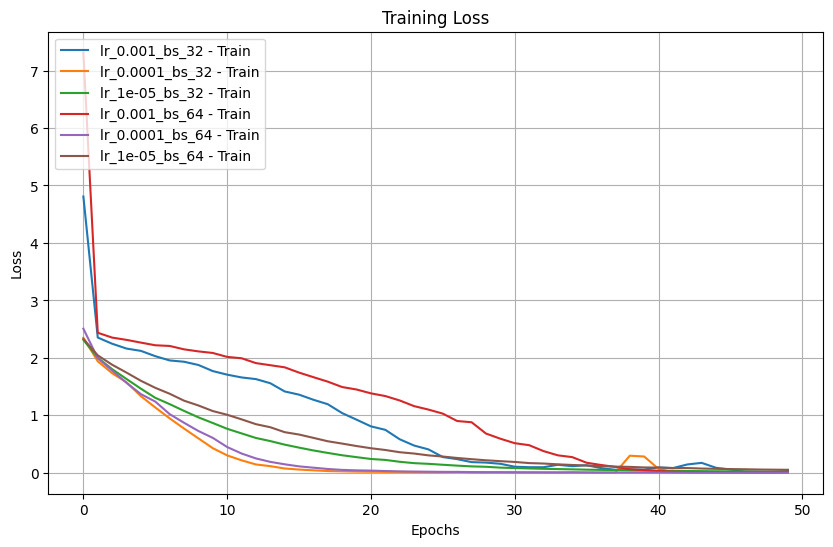

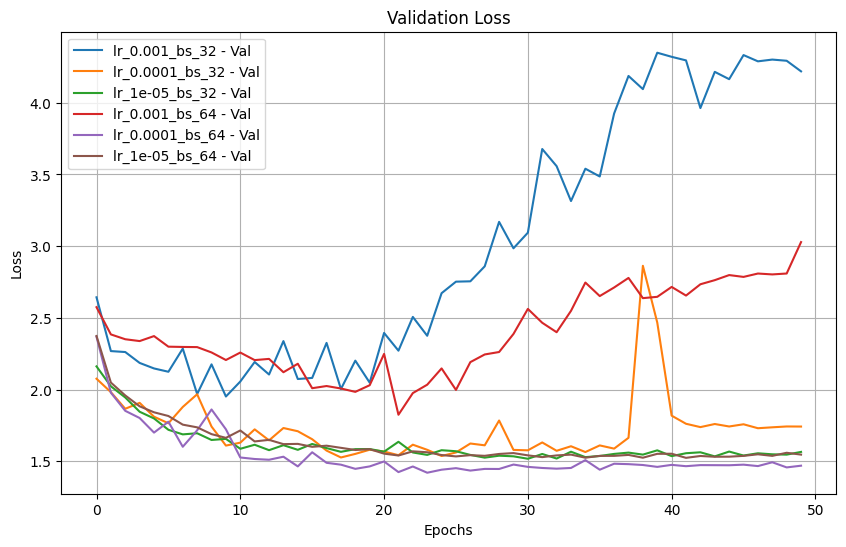

In [17]:
plot_results(results, metric='loss')

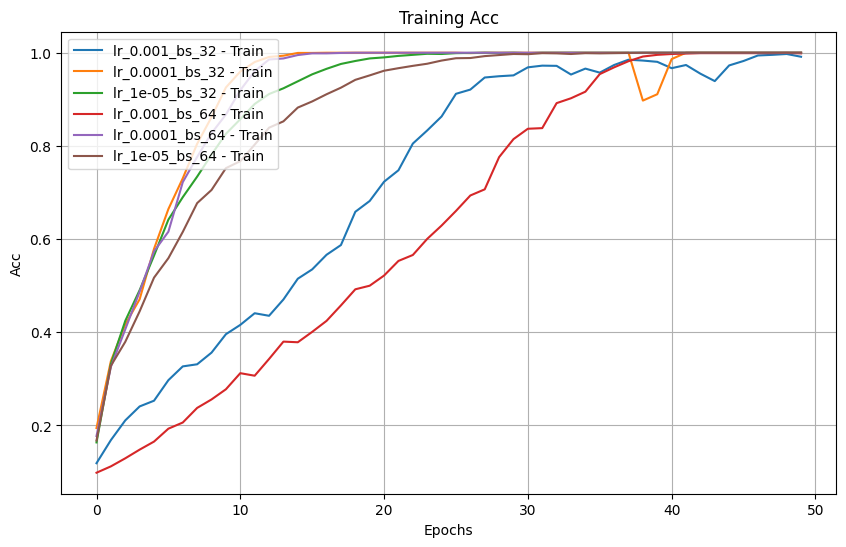

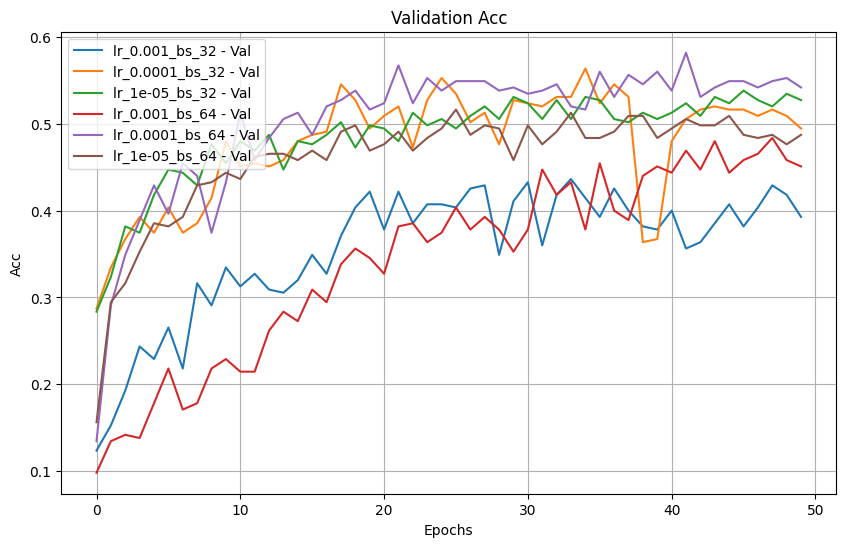

In [18]:
plot_results(results, metric='acc')

After conducting experiments with learning rates of 0.001, 0.0001, and 0.00001, and batch sizes of 32 and 64, I observed that the best results on the validation set were achieved with a learning rate of 0.0001 and a batch size of 32. Since most of the models achieved near-perfect accuracy on the training set, training accuracy was not a useful metric for evaluation. However, I noticed that while some models converged quickly, others took more time.

If we categorize the learning rates as large (0.001), optimal (0.0001), and small (0.00001), the large learning rate produced the worst results on the validation set—as expected, the two worst-performing configurations were both with the 0.001 learning rate, regardless of batch size. The small learning rate (0.00001) performed better than the large learning rate but worse than the optimal one.

These results are quite intuitive: the best performance was obtained with the 0.0001 learning rate, suggesting that trying values around this rate could further improve results.

When we examine batch sizes with 0.001 learning rate at start 32 batch size is better when we came to end the 64 batch size is better. When examine 0.0001 learning rate which is optimal 64 batch size is giving better performance. When examine 0.00001 learning rate which is smallest learning rate 32 batch size gives better performance so we can not say this batch size better.

In [19]:
residualResults = {}
for batch_size in batch_sizes:
    for lr in learning_rates:


        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        validation_loader = DataLoader(validation_dataset, batch_size=batch_size, shuffle=True)
        model = ResidualCNN(num_classes=11)
        print(f"\n===> Training with lr={lr}, batch_size={batch_size}")
        train_loss, val_loss, train_acc, val_acc = train_model(model, train_loader, validation_loader, lr)

        key = f"lr_{lr}_bs_{batch_size}"
        residualResults[key] = {
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_acc": train_acc,
            "val_acc": val_acc
        }


===> Training with lr=0.001, batch_size=32
Epoch [1/50] Train Loss: 3.5289, Train Acc: 0.1209 | Val Loss: 2.3387, Val Acc: 0.1564
Epoch [2/50] Train Loss: 2.2562, Train Acc: 0.1973 | Val Loss: 2.1976, Val Acc: 0.2109
Epoch [3/50] Train Loss: 2.1339, Train Acc: 0.2459 | Val Loss: 2.1974, Val Acc: 0.2327
Epoch [4/50] Train Loss: 1.9967, Train Acc: 0.3105 | Val Loss: 2.1275, Val Acc: 0.2473
Epoch [5/50] Train Loss: 1.8232, Train Acc: 0.3718 | Val Loss: 2.0236, Val Acc: 0.2655
Epoch [6/50] Train Loss: 1.6062, Train Acc: 0.4564 | Val Loss: 2.1633, Val Acc: 0.2764
Epoch [7/50] Train Loss: 1.3687, Train Acc: 0.5382 | Val Loss: 2.2341, Val Acc: 0.3164
Epoch [8/50] Train Loss: 1.1596, Train Acc: 0.6095 | Val Loss: 2.1638, Val Acc: 0.3200
Epoch [9/50] Train Loss: 0.8347, Train Acc: 0.7273 | Val Loss: 2.6154, Val Acc: 0.2982
Epoch [10/50] Train Loss: 0.5743, Train Acc: 0.8145 | Val Loss: 3.0223, Val Acc: 0.3091
Epoch [11/50] Train Loss: 0.3568, Train Acc: 0.8955 | Val Loss: 3.6005, Val Acc: 0.24

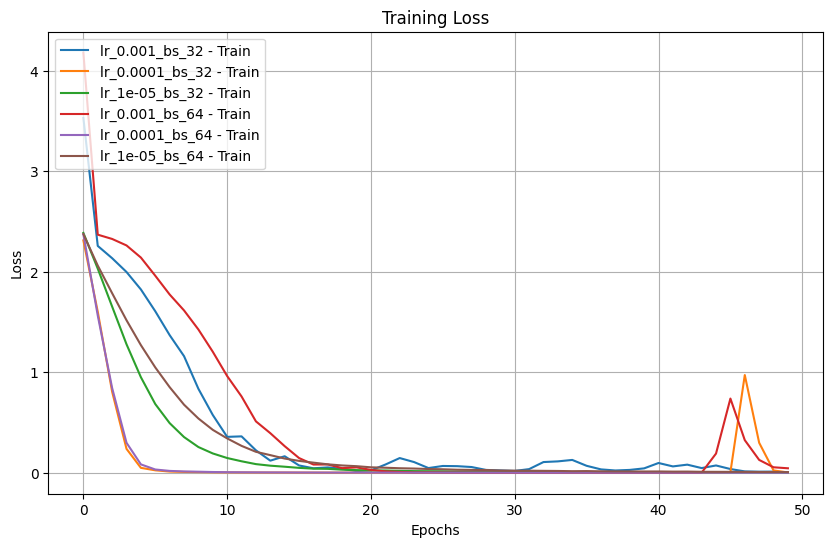

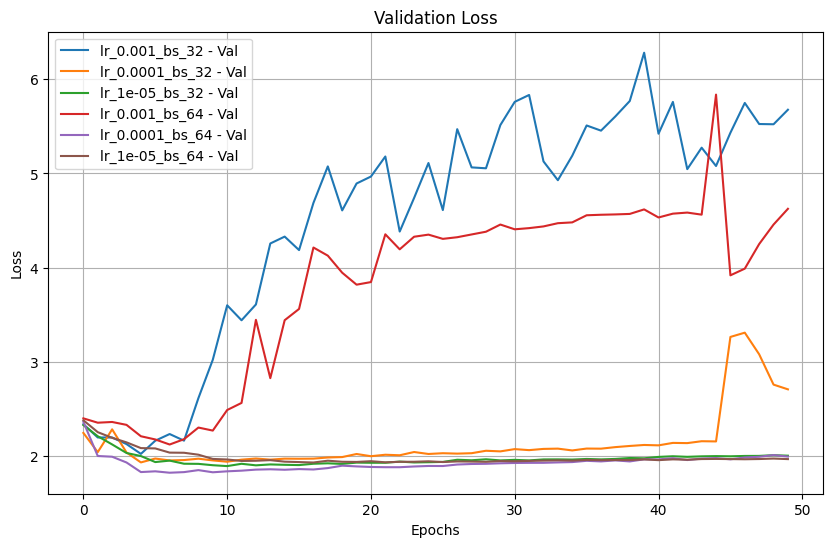

In [20]:
plot_results(residualResults, metric='loss')

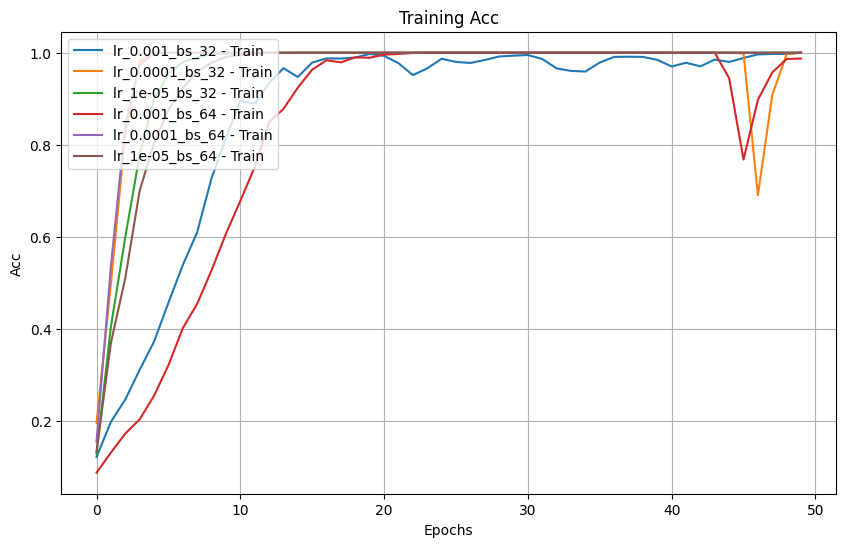

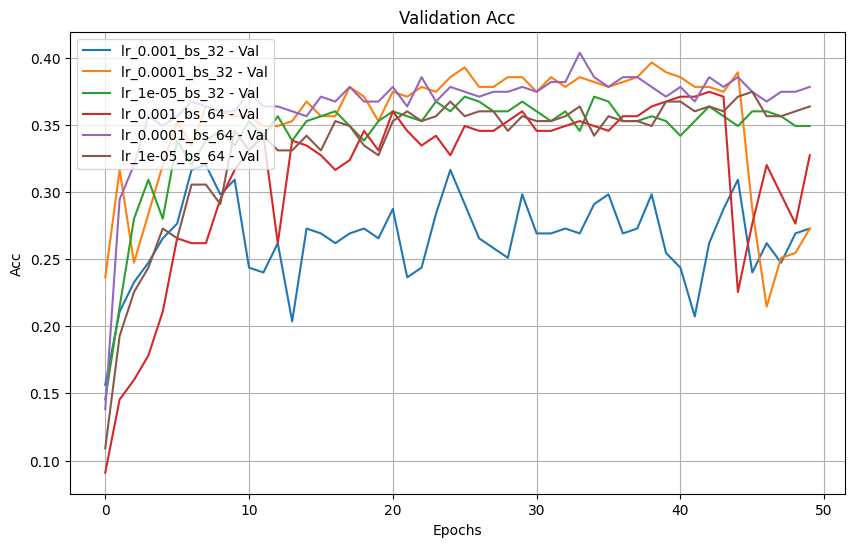

In [21]:
plot_results(residualResults, metric='acc')

The ResidualCNN model, which incorporates four stacked residual blocks along with an initial convolutional block and a fully connected classifier, was expected to outperform the baseline SimpleCNN due to its deeper architecture and skip connections that mitigate the vanishing gradient problem. However, based on the results, the validation accuracy plateaued around 40% across different configurations, which is notably lower than the peak validation accuracy achieved by the SimpleCNN. The learning rate of 0.0001 combined with both 32 and 64 batch sizes again provided the best results, but the performance gap between configurations was smaller than before. These findings suggest that while residual connections theoretically enable deeper networks to learn better representations, in this case, the added complexity may have led to overfitting or underfitting, possibly requiring further hyperparameter tuning or more training data to realize their full potential.

By the way, all of the models we used achieved an accuracy of 1 (or very close to 1) and near-zero loss on the training set. However, when evaluating the validation set, we observed that the performance was nowhere near the training set results, which is a clear indication of overfitting. To address this, we can simplify the model architecture to reduce its capacity, increase the size of the training dataset through data collection or extensive data augmentation, and apply regularization techniques such as dropout layers and weight decay (L2 regularization) to prevent the model from relying too heavily on specific features. Additionally, early stopping can be used to halt training when validation performance starts to degrade, while batch normalization and learning rate scheduling can further stabilize and improve training. Combining these strategies helps the model generalize better and reduces the risk of overfitting.

## **Best Models Test Performance (Simple CNN 1e-4 learning rate 64 batch / Residual CNN same parameters)**

In [22]:
def predict(model, test_loader):
    model.eval()
    model.to(device)

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.numpy())
    return all_preds, all_labels

In [23]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
validation_loader = DataLoader(validation_dataset, batch_size=64, shuffle=True)

In [25]:
simpleModel = SimpleCNN(num_classes=11)
simpleModelResults = train_model(simpleModel, train_loader, validation_loader, lr=1e-4)

Epoch [1/50] Train Loss: 2.5621, Train Acc: 0.1468 | Val Loss: 2.3306, Val Acc: 0.1418
Epoch [2/50] Train Loss: 2.0636, Train Acc: 0.3000 | Val Loss: 2.0096, Val Acc: 0.3527
Epoch [3/50] Train Loss: 1.8706, Train Acc: 0.3855 | Val Loss: 2.0136, Val Acc: 0.3273
Epoch [4/50] Train Loss: 1.6837, Train Acc: 0.4686 | Val Loss: 1.7669, Val Acc: 0.4218
Epoch [5/50] Train Loss: 1.5189, Train Acc: 0.5136 | Val Loss: 1.7841, Val Acc: 0.4036
Epoch [6/50] Train Loss: 1.3660, Train Acc: 0.5777 | Val Loss: 1.7332, Val Acc: 0.3891
Epoch [7/50] Train Loss: 1.1827, Train Acc: 0.6600 | Val Loss: 1.6530, Val Acc: 0.4400
Epoch [8/50] Train Loss: 1.0416, Train Acc: 0.6991 | Val Loss: 1.6206, Val Acc: 0.4364
Epoch [9/50] Train Loss: 0.8678, Train Acc: 0.7777 | Val Loss: 1.5698, Val Acc: 0.4982
Epoch [10/50] Train Loss: 0.7018, Train Acc: 0.8441 | Val Loss: 1.7419, Val Acc: 0.4145
Epoch [11/50] Train Loss: 0.5811, Train Acc: 0.8895 | Val Loss: 1.4771, Val Acc: 0.4873
Epoch [12/50] Train Loss: 0.4388, Train A

In [26]:
class_names = ['apple_pie','cheesecake','chicken_curry','french_fries','fried_rice','hamburger','hot_dog','ice_cream','omelette','pizza','sushi']

In [27]:
def predictionAndResults(model,testLoader,title):
  predictions, trueLabels = predict(model, testLoader)
  cm = confusion_matrix(trueLabels, predictions)
  disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
  disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
  plt.title(title)
  plt.show()

  precision = precision_score(trueLabels, predictions, average='macro')
  recall = recall_score(trueLabels, predictions, average='macro')
  f1 = f1_score(trueLabels, predictions, average='macro')

  print(f"Precision: {precision:.4f}")
  print(f"Recall: {recall:.4f}")
  print(f"F1 Score: {f1:.4f}")

  report = classification_report(trueLabels, predictions, target_names=class_names)
  print(report)


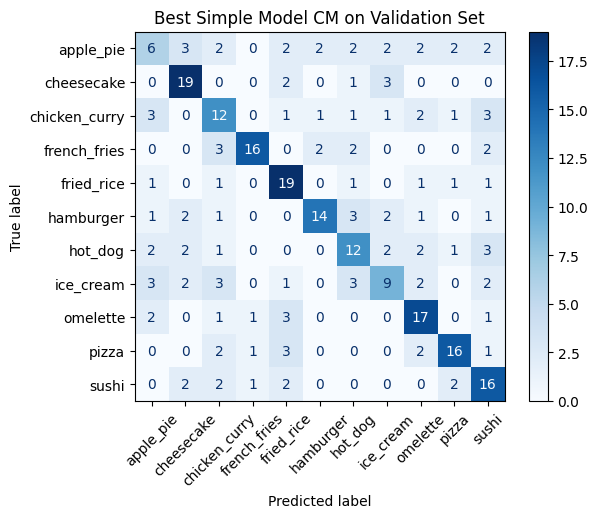

Precision: 0.5714
Recall: 0.5673
F1 Score: 0.5626
               precision    recall  f1-score   support

    apple_pie       0.33      0.24      0.28        25
   cheesecake       0.63      0.76      0.69        25
chicken_curry       0.43      0.48      0.45        25
 french_fries       0.84      0.64      0.73        25
   fried_rice       0.58      0.76      0.66        25
    hamburger       0.74      0.56      0.64        25
      hot_dog       0.48      0.48      0.48        25
    ice_cream       0.47      0.36      0.41        25
     omelette       0.59      0.68      0.63        25
        pizza       0.70      0.64      0.67        25
        sushi       0.50      0.64      0.56        25

     accuracy                           0.57       275
    macro avg       0.57      0.57      0.56       275
 weighted avg       0.57      0.57      0.56       275



In [29]:
predictionAndResults(simpleModel, validation_loader,'Best Simple Model CM on Validation Set')

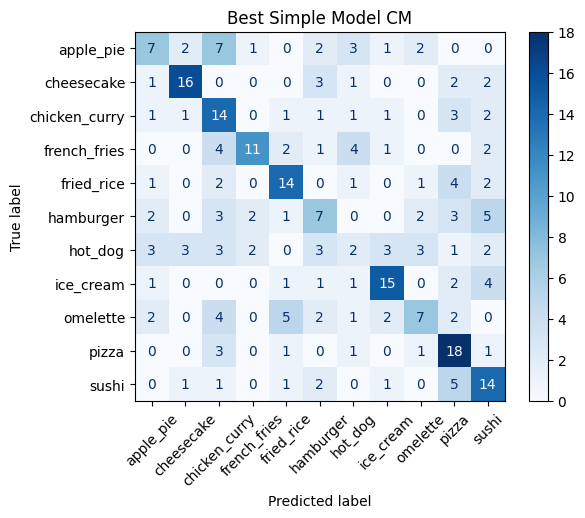

Precision: 0.4571
Recall: 0.4545
F1 Score: 0.4438
               precision    recall  f1-score   support

    apple_pie       0.39      0.28      0.33        25
   cheesecake       0.70      0.64      0.67        25
chicken_curry       0.34      0.56      0.42        25
 french_fries       0.69      0.44      0.54        25
   fried_rice       0.54      0.56      0.55        25
    hamburger       0.32      0.28      0.30        25
      hot_dog       0.13      0.08      0.10        25
    ice_cream       0.62      0.60      0.61        25
     omelette       0.44      0.28      0.34        25
        pizza       0.45      0.72      0.55        25
        sushi       0.41      0.56      0.47        25

     accuracy                           0.45       275
    macro avg       0.46      0.45      0.44       275
 weighted avg       0.46      0.45      0.44       275



In [28]:
predictionAndResults(simpleModel, test_loader,'Best Simple Model CM on Test Set')

We can see that our model give better performance on validation set it probably because of the train set more similar to validation set than test set.

In [30]:
residualModel = ResidualCNN(num_classes=11)
train_loss, val_loss, train_acc, val_acc = train_model(residualModel, train_loader, validation_loader, lr=1e-4)

Epoch [1/50] Train Loss: 2.3165, Train Acc: 0.1868 | Val Loss: 2.2646, Val Acc: 0.1891
Epoch [2/50] Train Loss: 1.4669, Train Acc: 0.5882 | Val Loss: 2.0561, Val Acc: 0.2655
Epoch [3/50] Train Loss: 0.7260, Train Acc: 0.8836 | Val Loss: 1.9108, Val Acc: 0.3345
Epoch [4/50] Train Loss: 0.2083, Train Acc: 0.9923 | Val Loss: 1.9346, Val Acc: 0.3200
Epoch [5/50] Train Loss: 0.0654, Train Acc: 1.0000 | Val Loss: 1.8544, Val Acc: 0.3309
Epoch [6/50] Train Loss: 0.0262, Train Acc: 1.0000 | Val Loss: 1.8187, Val Acc: 0.3673
Epoch [7/50] Train Loss: 0.0149, Train Acc: 1.0000 | Val Loss: 1.8280, Val Acc: 0.3673
Epoch [8/50] Train Loss: 0.0116, Train Acc: 1.0000 | Val Loss: 1.8483, Val Acc: 0.3709
Epoch [9/50] Train Loss: 0.0084, Train Acc: 1.0000 | Val Loss: 1.8426, Val Acc: 0.3636
Epoch [10/50] Train Loss: 0.0061, Train Acc: 1.0000 | Val Loss: 1.8372, Val Acc: 0.3564
Epoch [11/50] Train Loss: 0.0054, Train Acc: 1.0000 | Val Loss: 1.8435, Val Acc: 0.3673
Epoch [12/50] Train Loss: 0.0050, Train A

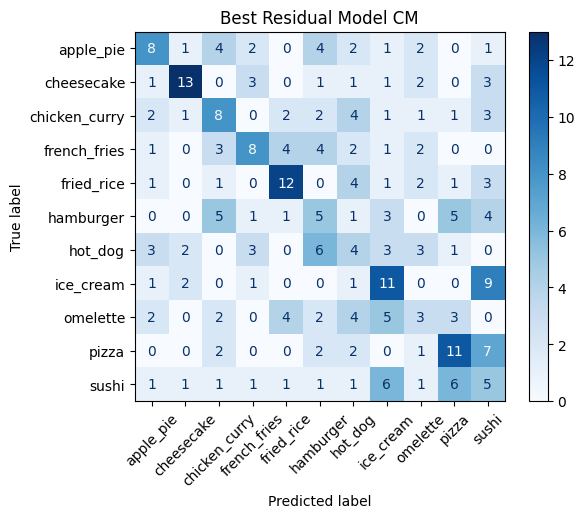

Precision: 0.3330
Recall: 0.3200
F1 Score: 0.3231
               precision    recall  f1-score   support

    apple_pie       0.40      0.32      0.36        25
   cheesecake       0.65      0.52      0.58        25
chicken_curry       0.31      0.32      0.31        25
 french_fries       0.42      0.32      0.36        25
   fried_rice       0.50      0.48      0.49        25
    hamburger       0.19      0.20      0.19        25
      hot_dog       0.15      0.16      0.16        25
    ice_cream       0.33      0.44      0.38        25
     omelette       0.18      0.12      0.14        25
        pizza       0.39      0.44      0.42        25
        sushi       0.14      0.20      0.17        25

     accuracy                           0.32       275
    macro avg       0.33      0.32      0.32       275
 weighted avg       0.33      0.32      0.32       275



In [31]:
predictionAndResults(residualModel, test_loader, 'Best Residual Model CM')

In our experiments, the SimpleCNN model consistently outperformed the ResidualCNN model across both validation and test sets. While SimpleCNN achieved a peak validation accuracy of around 57% and a test accuracy of 45%, ResidualCNN lagged behind with approximately 39% validation accuracy and 32% test accuracy. Precision, recall, and F1 scores mirrored this pattern, with SimpleCNN maintaining balanced and stronger results across all metrics. Although ResidualCNN is designed to enable deeper architectures and theoretically improve generalization, in this case, its added complexity did not translate into better performance—likely due to limited dataset size and potential overfitting. SimpleCNN’s simpler structure proved more robust for the current task, highlighting that deeper networks do not always guarantee better results without sufficient data or additional regularization. Future improvements could focus on expanding the dataset, enhancing regularization, and fine-tuning hyperparameters to fully leverage the potential of deeper architectures.

# **DropOut Tests**

In [32]:
dropoutSimpleModel = SimpleCNN(num_classes=11, dropout_rate=0.2)
train_loss, val_loss, train_acc, val_acc = train_model(dropoutSimpleModel, train_loader, validation_loader, lr=1e-4)

Epoch [1/50] Train Loss: 2.4006, Train Acc: 0.1764 | Val Loss: 2.3649, Val Acc: 0.1891
Epoch [2/50] Train Loss: 1.9676, Train Acc: 0.3264 | Val Loss: 2.0386, Val Acc: 0.3018
Epoch [3/50] Train Loss: 1.7823, Train Acc: 0.3991 | Val Loss: 1.9608, Val Acc: 0.3455
Epoch [4/50] Train Loss: 1.6414, Train Acc: 0.4595 | Val Loss: 1.7660, Val Acc: 0.4000
Epoch [5/50] Train Loss: 1.4200, Train Acc: 0.5405 | Val Loss: 1.6951, Val Acc: 0.4327
Epoch [6/50] Train Loss: 1.2000, Train Acc: 0.6332 | Val Loss: 1.6729, Val Acc: 0.4364
Epoch [7/50] Train Loss: 1.0412, Train Acc: 0.6900 | Val Loss: 1.7996, Val Acc: 0.3964
Epoch [8/50] Train Loss: 0.8990, Train Acc: 0.7432 | Val Loss: 1.7855, Val Acc: 0.4218
Epoch [9/50] Train Loss: 0.7696, Train Acc: 0.7918 | Val Loss: 1.5482, Val Acc: 0.4545
Epoch [10/50] Train Loss: 0.5723, Train Acc: 0.8618 | Val Loss: 1.5895, Val Acc: 0.4982
Epoch [11/50] Train Loss: 0.4604, Train Acc: 0.9086 | Val Loss: 1.6397, Val Acc: 0.4691
Epoch [12/50] Train Loss: 0.3555, Train A

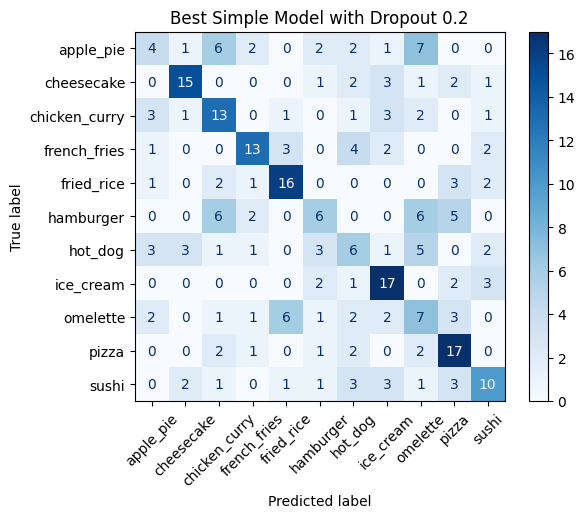

Precision: 0.4471
Recall: 0.4509
F1 Score: 0.4422
               precision    recall  f1-score   support

    apple_pie       0.29      0.16      0.21        25
   cheesecake       0.68      0.60      0.64        25
chicken_curry       0.41      0.52      0.46        25
 french_fries       0.62      0.52      0.57        25
   fried_rice       0.59      0.64      0.62        25
    hamburger       0.35      0.24      0.29        25
      hot_dog       0.26      0.24      0.25        25
    ice_cream       0.53      0.68      0.60        25
     omelette       0.23      0.28      0.25        25
        pizza       0.49      0.68      0.57        25
        sushi       0.48      0.40      0.43        25

     accuracy                           0.45       275
    macro avg       0.45      0.45      0.44       275
 weighted avg       0.45      0.45      0.44       275



In [33]:
predictionAndResults(dropoutSimpleModel, test_loader, 'Best Simple Model with Dropout 0.2')

After adding 0.2 dropout to the SimpleCNN model, the test set results showed minimal change compared to the original model. The accuracy remained at 45%, while precision, recall, and F1 score slightly decreased from 0.4571, 0.4545, and 0.4438 to 0.4471, 0.4509, and 0.4422, respectively. This indicates that introducing dropout did not significantly impact performance—likely because the model was already relatively stable, or the dataset size was not sufficient for dropout to make a noticeable difference. While dropout is a well-known regularization technique to reduce overfitting, in this case, it neither improved nor harmed the model’s ability to generalize. Further improvements may require stronger regularization, more data, or additional techniques such as data augmentation or learning rate scheduling.

In [34]:
dropoutSimpleBigger = SimpleCNN(num_classes=11, dropout_rate=0.5)
train_loss, val_loss, train_acc, val_acc = train_model(dropoutSimpleBigger, train_loader, validation_loader, lr=1e-4)

Epoch [1/50] Train Loss: 2.4042, Train Acc: 0.1614 | Val Loss: 2.2873, Val Acc: 0.1564
Epoch [2/50] Train Loss: 2.0776, Train Acc: 0.2791 | Val Loss: 1.9856, Val Acc: 0.3164
Epoch [3/50] Train Loss: 1.9445, Train Acc: 0.3291 | Val Loss: 1.8724, Val Acc: 0.4073
Epoch [4/50] Train Loss: 1.8431, Train Acc: 0.3805 | Val Loss: 1.8538, Val Acc: 0.3855
Epoch [5/50] Train Loss: 1.7210, Train Acc: 0.4205 | Val Loss: 1.8172, Val Acc: 0.3636
Epoch [6/50] Train Loss: 1.6118, Train Acc: 0.4459 | Val Loss: 1.7638, Val Acc: 0.3964
Epoch [7/50] Train Loss: 1.4701, Train Acc: 0.5236 | Val Loss: 1.6913, Val Acc: 0.4109
Epoch [8/50] Train Loss: 1.3743, Train Acc: 0.5459 | Val Loss: 1.6233, Val Acc: 0.4764
Epoch [9/50] Train Loss: 1.2261, Train Acc: 0.6068 | Val Loss: 1.6339, Val Acc: 0.4364
Epoch [10/50] Train Loss: 1.1761, Train Acc: 0.6282 | Val Loss: 1.5303, Val Acc: 0.4945
Epoch [11/50] Train Loss: 1.0284, Train Acc: 0.6809 | Val Loss: 1.6471, Val Acc: 0.4327
Epoch [12/50] Train Loss: 0.9111, Train A

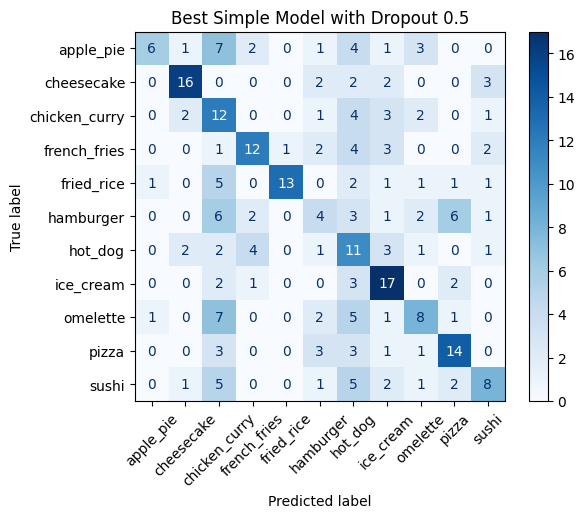

Precision: 0.5098
Recall: 0.4400
F1 Score: 0.4467
               precision    recall  f1-score   support

    apple_pie       0.75      0.24      0.36        25
   cheesecake       0.73      0.64      0.68        25
chicken_curry       0.24      0.48      0.32        25
 french_fries       0.57      0.48      0.52        25
   fried_rice       0.93      0.52      0.67        25
    hamburger       0.24      0.16      0.19        25
      hot_dog       0.24      0.44      0.31        25
    ice_cream       0.49      0.68      0.57        25
     omelette       0.42      0.32      0.36        25
        pizza       0.54      0.56      0.55        25
        sushi       0.47      0.32      0.38        25

     accuracy                           0.44       275
    macro avg       0.51      0.44      0.45       275
 weighted avg       0.51      0.44      0.45       275



In [35]:
predictionAndResults(dropoutSimpleBigger, test_loader, 'Best Simple Model with Dropout 0.5')

After increasing the dropout rate to 0.5 in the SimpleCNN model, the test results showed a slight shift in performance. While the overall accuracy decreased slightly from 0.45 to 0.44, precision improved noticeably from around 0.45 to 0.51, indicating that the model became more conservative and made fewer false positive predictions. However, recall dropped slightly, reflecting that the model missed more true positives compared to previous runs. The F1 score showed a minor improvement, rising from about 0.44 to 0.4467, suggesting a slightly better balance between precision and recall. These results indicate that a higher dropout rate made the model more selective, which can be beneficial in scenarios where precision is more critical than recall. However, in terms of overall accuracy and balance, no significant improvement was observed.

In [36]:
dropoutResidual = ResidualCNN(num_classes=11, dropout_rate=0.2)
train_loss, val_loss, train_acc, val_acc = train_model(dropoutResidual, train_loader, validation_loader, lr=1e-4)

Epoch [1/50] Train Loss: 2.3634, Train Acc: 0.1709 | Val Loss: 2.2674, Val Acc: 0.2000
Epoch [2/50] Train Loss: 1.7313, Train Acc: 0.4491 | Val Loss: 2.0778, Val Acc: 0.2727
Epoch [3/50] Train Loss: 1.1274, Train Acc: 0.6955 | Val Loss: 1.9585, Val Acc: 0.3309
Epoch [4/50] Train Loss: 0.4918, Train Acc: 0.9400 | Val Loss: 1.8968, Val Acc: 0.3564
Epoch [5/50] Train Loss: 0.1805, Train Acc: 0.9927 | Val Loss: 1.8665, Val Acc: 0.3636
Epoch [6/50] Train Loss: 0.0760, Train Acc: 0.9986 | Val Loss: 1.8599, Val Acc: 0.3673
Epoch [7/50] Train Loss: 0.0371, Train Acc: 1.0000 | Val Loss: 1.8612, Val Acc: 0.3818
Epoch [8/50] Train Loss: 0.0235, Train Acc: 1.0000 | Val Loss: 1.8295, Val Acc: 0.3745
Epoch [9/50] Train Loss: 0.0155, Train Acc: 1.0000 | Val Loss: 1.8355, Val Acc: 0.3855
Epoch [10/50] Train Loss: 0.0120, Train Acc: 1.0000 | Val Loss: 1.8613, Val Acc: 0.3782
Epoch [11/50] Train Loss: 0.0102, Train Acc: 1.0000 | Val Loss: 1.8738, Val Acc: 0.3745
Epoch [12/50] Train Loss: 0.0081, Train A

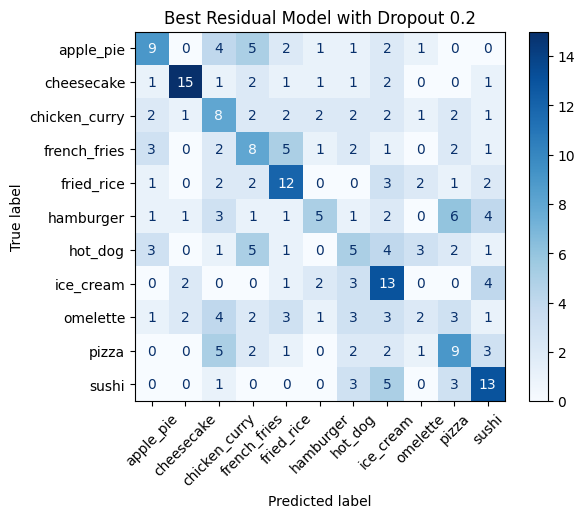

Precision: 0.3606
Recall: 0.3600
F1 Score: 0.3514
               precision    recall  f1-score   support

    apple_pie       0.43      0.36      0.39        25
   cheesecake       0.71      0.60      0.65        25
chicken_curry       0.26      0.32      0.29        25
 french_fries       0.28      0.32      0.30        25
   fried_rice       0.41      0.48      0.44        25
    hamburger       0.38      0.20      0.26        25
      hot_dog       0.22      0.20      0.21        25
    ice_cream       0.33      0.52      0.41        25
     omelette       0.20      0.08      0.11        25
        pizza       0.32      0.36      0.34        25
        sushi       0.42      0.52      0.46        25

     accuracy                           0.36       275
    macro avg       0.36      0.36      0.35       275
 weighted avg       0.36      0.36      0.35       275



In [37]:
predictionAndResults(dropoutResidual, test_loader, 'Best Residual Model with Dropout 0.2')

After adding 0.2 dropout to the ResidualCNN model, the test performance improved noticeably compared to the original model without dropout. The accuracy increased from 0.32 to 0.36, and both precision and recall rose from around 0.33 to approximately 0.36. The F1 score also improved from 0.3231 to 0.3514, indicating a better balance between precision and recall. These results suggest that introducing dropout helped reduce overfitting and allowed the ResidualCNN to generalize better on the test set. Although the model’s performance still lags behind the best results achieved by SimpleCNN, this experiment demonstrates that regularization can positively impact deeper architectures like ResidualCNN.

In [38]:
dropoutResidualBigger = ResidualCNN(num_classes=11, dropout_rate=0.5)
train_loss, val_loss, train_acc, val_acc = train_model(dropoutResidualBigger, train_loader, validation_loader, lr=1e-4)

Epoch [1/50] Train Loss: 2.4187, Train Acc: 0.1373 | Val Loss: 2.3284, Val Acc: 0.1455
Epoch [2/50] Train Loss: 1.9505, Train Acc: 0.3364 | Val Loss: 2.1215, Val Acc: 0.2545
Epoch [3/50] Train Loss: 1.5610, Train Acc: 0.5105 | Val Loss: 1.9450, Val Acc: 0.3418
Epoch [4/50] Train Loss: 1.1066, Train Acc: 0.7036 | Val Loss: 1.8662, Val Acc: 0.3782
Epoch [5/50] Train Loss: 0.6455, Train Acc: 0.8750 | Val Loss: 1.8922, Val Acc: 0.3636
Epoch [6/50] Train Loss: 0.3137, Train Acc: 0.9645 | Val Loss: 1.8381, Val Acc: 0.3418
Epoch [7/50] Train Loss: 0.1497, Train Acc: 0.9905 | Val Loss: 1.8808, Val Acc: 0.3600
Epoch [8/50] Train Loss: 0.0903, Train Acc: 0.9968 | Val Loss: 1.8675, Val Acc: 0.3891
Epoch [9/50] Train Loss: 0.0560, Train Acc: 0.9986 | Val Loss: 1.7916, Val Acc: 0.3855
Epoch [10/50] Train Loss: 0.0405, Train Acc: 0.9995 | Val Loss: 1.8197, Val Acc: 0.4036
Epoch [11/50] Train Loss: 0.0262, Train Acc: 1.0000 | Val Loss: 1.8541, Val Acc: 0.3927
Epoch [12/50] Train Loss: 0.0213, Train A

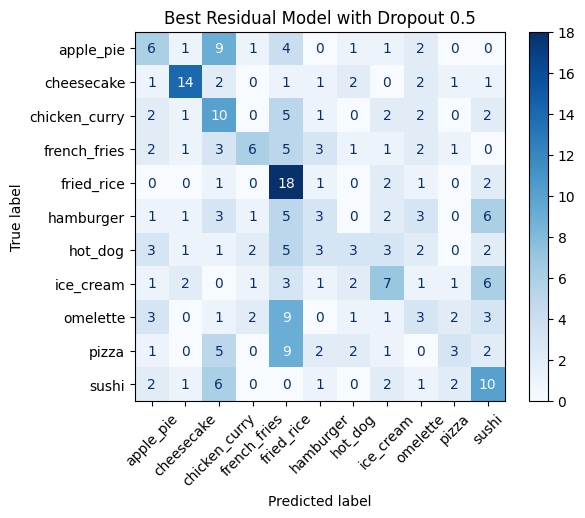

Precision: 0.3094
Recall: 0.3018
F1 Score: 0.2843
               precision    recall  f1-score   support

    apple_pie       0.27      0.24      0.26        25
   cheesecake       0.64      0.56      0.60        25
chicken_curry       0.24      0.40      0.30        25
 french_fries       0.46      0.24      0.32        25
   fried_rice       0.28      0.72      0.40        25
    hamburger       0.19      0.12      0.15        25
      hot_dog       0.25      0.12      0.16        25
    ice_cream       0.32      0.28      0.30        25
     omelette       0.16      0.12      0.14        25
        pizza       0.30      0.12      0.17        25
        sushi       0.29      0.40      0.34        25

     accuracy                           0.30       275
    macro avg       0.31      0.30      0.28       275
 weighted avg       0.31      0.30      0.28       275



In [39]:
predictionAndResults(dropoutResidualBigger, test_loader, 'Best Residual Model with Dropout 0.5')

After increasing the dropout rate to 0.5 in the ResidualCNN model, the test performance declined across all metrics. Accuracy dropped from 0.36 to 0.30, while precision and recall decreased from approximately 0.36 to around 0.31 and 0.30, respectively. The F1 score also fell from 0.3514 to 0.2843, indicating a noticeable reduction in the model’s overall balance and effectiveness. These results suggest that while moderate dropout (such as 0.2) helped reduce overfitting and improved generalization, a higher dropout rate of 0.5 introduced too much regularization, limiting the model’s ability to learn effectively. This demonstrates that tuning regularization parameters is crucial, as overly aggressive dropout can harm model performance.


In our experiments, dropout proved to be an effective tool for controlling overfitting, but its impact varied depending on the model architecture and the dropout rate applied. For the SimpleCNN model, introducing dropout at 0.2 had minimal effect, with test performance remaining almost unchanged, while 0.5 dropout slightly increased precision but reduced recall, showing a trade-off between making more precise predictions and missing some true positives. In contrast, the ResidualCNN model benefited noticeably from a 0.2 dropout rate, with accuracy improving from 0.32 to 0.36, indicating that moderate dropout helped the deeper network generalize better. However, when the dropout rate was increased to 0.5, the performance dropped significantly across all metrics, suggesting that too much regularization hindered the model’s learning capacity. These results highlight that while dropout can effectively reduce overfitting and improve generalization, its success is sensitive to both the architecture and the chosen rate. Optimal dropout tuning is essential to strike the right balance between underfitting and overfitting.

# **BEST MODEL 0.0001 LEARNİNG RATE 64 BATCH **

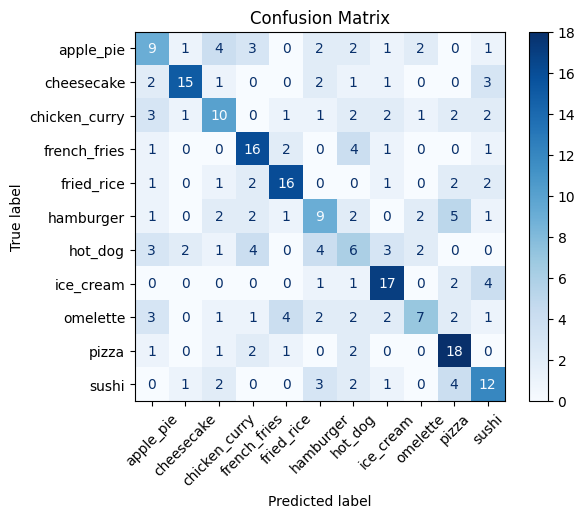

Precision: 0.4912
Recall: 0.4909
F1 Score: 0.4850
               precision    recall  f1-score   support

    apple_pie       0.38      0.36      0.37        25
   cheesecake       0.75      0.60      0.67        25
chicken_curry       0.43      0.40      0.42        25
 french_fries       0.53      0.64      0.58        25
   fried_rice       0.64      0.64      0.64        25
    hamburger       0.38      0.36      0.37        25
      hot_dog       0.25      0.24      0.24        25
    ice_cream       0.59      0.68      0.63        25
     omelette       0.50      0.28      0.36        25
        pizza       0.51      0.72      0.60        25
        sushi       0.44      0.48      0.46        25

     accuracy                           0.49       275
    macro avg       0.49      0.49      0.48       275
 weighted avg       0.49      0.49      0.48       275



In [ ]:
predictionAndResults(simpleModel, test_loader, 'Best Model Simple 1e-4 64')

# **PART 2**

What is fine-tuning? Why should we do this? Why do we freeze the rest and train only FC layers?

Fine-tuning is the process of taking a pre-trained deep learning model—typically trained on a large and general dataset like ImageNet—and adapting it to a specific task. Training deep networks from scratch requires significant computational resources and a large amount of data. However, many features learned by early layers of these models (such as edges, textures, and simple shapes) are general and transferable across different tasks. Deeper layers tend to capture task-specific features.

By using a pre-trained model, we leverage this prior knowledge. In most cases, we freeze the early layers and only train the fully connected (FC) layers at the end of the model. This is because the early layers already extract meaningful low-level features, and updating them would be unnecessary and computationally expensive. Training only the FC layers allows us to quickly adapt the model to our specific dataset with fewer parameters and less risk of overfitting.

**train only FC layer and freeze rest**

In [43]:
preTrainedModel = models.mobilenet_v2(weights=MobileNet_V2_Weights.DEFAULT)

for param in preTrainedModel.parameters():
    param.requires_grad = False


num_features = preTrainedModel.classifier[1].in_features
preTrainedModel.classifier[1] = nn.Linear(num_features, len(class_names))

optimizer = torch.optim.Adam(preTrainedModel.classifier[1].parameters(), lr=1e-4)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth
100%|██████████| 13.6M/13.6M [00:00<00:00, 203MB/s]


In [44]:
train_losses, val_losses, train_accs, val_accs = train_model(
    preTrainedModel, train_loader, validation_loader, lr=1e-4, num_epochs=50
)

Epoch [1/50] Train Loss: 2.3569, Train Acc: 0.1450 | Val Loss: 2.2945, Val Acc: 0.2545
Epoch [2/50] Train Loss: 2.2710, Train Acc: 0.2682 | Val Loss: 2.2073, Val Acc: 0.4145
Epoch [3/50] Train Loss: 2.1858, Train Acc: 0.3932 | Val Loss: 2.1218, Val Acc: 0.5709
Epoch [4/50] Train Loss: 2.1072, Train Acc: 0.4900 | Val Loss: 2.0481, Val Acc: 0.6618
Epoch [5/50] Train Loss: 2.0317, Train Acc: 0.5591 | Val Loss: 1.9677, Val Acc: 0.7018
Epoch [6/50] Train Loss: 1.9679, Train Acc: 0.6032 | Val Loss: 1.8945, Val Acc: 0.7345
Epoch [7/50] Train Loss: 1.8991, Train Acc: 0.6441 | Val Loss: 1.8298, Val Acc: 0.7600
Epoch [8/50] Train Loss: 1.8348, Train Acc: 0.6650 | Val Loss: 1.7694, Val Acc: 0.7636
Epoch [9/50] Train Loss: 1.7819, Train Acc: 0.6741 | Val Loss: 1.7123, Val Acc: 0.7673
Epoch [10/50] Train Loss: 1.7282, Train Acc: 0.6932 | Val Loss: 1.6514, Val Acc: 0.7782
Epoch [11/50] Train Loss: 1.6721, Train Acc: 0.7059 | Val Loss: 1.5988, Val Acc: 0.7964
Epoch [12/50] Train Loss: 1.6248, Train A

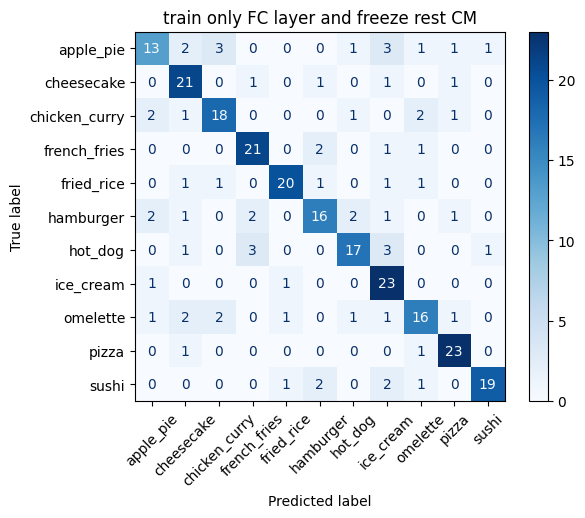

Precision: 0.7584
Recall: 0.7527
F1 Score: 0.7499
               precision    recall  f1-score   support

    apple_pie       0.68      0.52      0.59        25
   cheesecake       0.70      0.84      0.76        25
chicken_curry       0.75      0.72      0.73        25
 french_fries       0.78      0.84      0.81        25
   fried_rice       0.87      0.80      0.83        25
    hamburger       0.73      0.64      0.68        25
      hot_dog       0.77      0.68      0.72        25
    ice_cream       0.64      0.92      0.75        25
     omelette       0.70      0.64      0.67        25
        pizza       0.82      0.92      0.87        25
        sushi       0.90      0.76      0.83        25

     accuracy                           0.75       275
    macro avg       0.76      0.75      0.75       275
 weighted avg       0.76      0.75      0.75       275



In [46]:
predictionAndResults(preTrainedModel,test_loader,'train only FC layer and freeze rest CM')

**train last two convolutional layers and FC layer and freeze rest**

In [48]:
moreTrainModel = models.mobilenet_v2(weights=MobileNet_V2_Weights.DEFAULT)

for param in moreTrainModel.parameters():
    param.requires_grad = False

for param in moreTrainModel.features[-1].parameters():
    param.requires_grad = True
for param in moreTrainModel.features[-2].parameters():
    param.requires_grad = True

num_features = moreTrainModel.classifier[1].in_features
moreTrainModel.classifier[1] = nn.Linear(num_features, len(class_names))

for param in moreTrainModel.classifier[1].parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, moreTrainModel.parameters()), lr=1e-4)

In [49]:
train_losses, val_losses, train_accs, val_accs = train_model(
    moreTrainModel, train_loader, validation_loader, lr=1e-4, num_epochs=50
)

Epoch [1/50] Train Loss: 2.2898, Train Acc: 0.2218 | Val Loss: 2.0803, Val Acc: 0.6182
Epoch [2/50] Train Loss: 1.9311, Train Acc: 0.6241 | Val Loss: 1.6576, Val Acc: 0.7855
Epoch [3/50] Train Loss: 1.5456, Train Acc: 0.7168 | Val Loss: 1.2549, Val Acc: 0.8255
Epoch [4/50] Train Loss: 1.2381, Train Acc: 0.7605 | Val Loss: 0.9712, Val Acc: 0.8545
Epoch [5/50] Train Loss: 1.0215, Train Acc: 0.7823 | Val Loss: 0.7723, Val Acc: 0.8618
Epoch [6/50] Train Loss: 0.8590, Train Acc: 0.8032 | Val Loss: 0.6361, Val Acc: 0.8727
Epoch [7/50] Train Loss: 0.7426, Train Acc: 0.8264 | Val Loss: 0.5587, Val Acc: 0.8800
Epoch [8/50] Train Loss: 0.6554, Train Acc: 0.8345 | Val Loss: 0.4961, Val Acc: 0.9018
Epoch [9/50] Train Loss: 0.5855, Train Acc: 0.8500 | Val Loss: 0.4457, Val Acc: 0.9018
Epoch [10/50] Train Loss: 0.5310, Train Acc: 0.8691 | Val Loss: 0.4241, Val Acc: 0.9127
Epoch [11/50] Train Loss: 0.4737, Train Acc: 0.8855 | Val Loss: 0.3959, Val Acc: 0.9127
Epoch [12/50] Train Loss: 0.4335, Train A

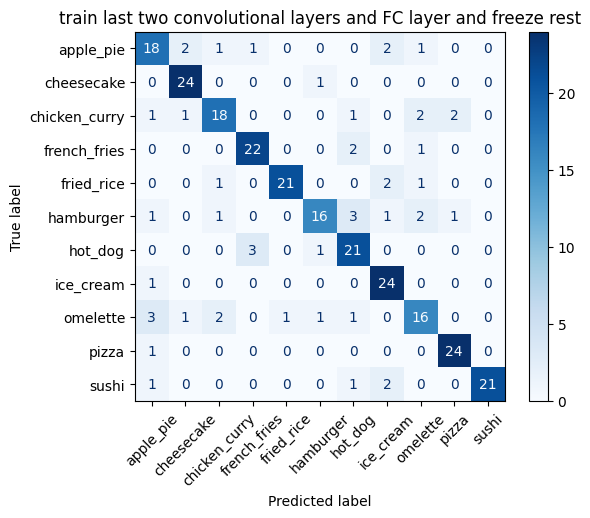

Precision: 0.8234
Recall: 0.8182
F1 Score: 0.8166
               precision    recall  f1-score   support

    apple_pie       0.69      0.72      0.71        25
   cheesecake       0.86      0.96      0.91        25
chicken_curry       0.78      0.72      0.75        25
 french_fries       0.85      0.88      0.86        25
   fried_rice       0.95      0.84      0.89        25
    hamburger       0.84      0.64      0.73        25
      hot_dog       0.72      0.84      0.78        25
    ice_cream       0.77      0.96      0.86        25
     omelette       0.70      0.64      0.67        25
        pizza       0.89      0.96      0.92        25
        sushi       1.00      0.84      0.91        25

     accuracy                           0.82       275
    macro avg       0.82      0.82      0.82       275
 weighted avg       0.82      0.82      0.82       275



In [50]:
predictionAndResults(moreTrainModel,test_loader,'train last two convolutional layers and FC layer and freeze rest')

When comparing the two fine-tuning strategies applied to MobileNetV2, it is clear that training the last two convolutional layers along with the fully connected (FC) layer produced significantly better results than training only the FC layer. The model that included the last two convolutional layers achieved an accuracy of 0.82, with precision, recall, and F1 scores all around 0.82, indicating strong and balanced performance. In contrast, the model that trained only the FC layer reached 0.75 accuracy, with precision, recall, and F1 scores around 0.75 as well. This demonstrates that while training only the FC layer can provide solid results with minimal computational cost, allowing deeper layers to be updated enables the model to adapt its feature extraction process to the specific dataset, leading to a clear improvement in performance.

When comparing our custom-built models with the transfer learning approaches using MobileNetV2, the advantage of transfer learning becomes very clear. While the best result from our SimpleCNN reached around 45% accuracy and the ResidualCNN around 36%, the MobileNetV2 model—trained only on the fully connected layer—already achieved 75% accuracy. This performance improved further to 82% accuracy when the last two convolutional layers were also fine-tuned alongside the FC layer. These results highlight that although building and training models from scratch is valuable for understanding architecture design and learning mechanics, transfer learning provides a significant boost in performance, especially when working with limited data. Leveraging pre-trained models allows for much better feature extraction and generalization, demonstrating why transfer learning is a widely adopted strategy in practical deep learning tasks.